# FIT5202 Assignment 2A : Building ML Models for Smart Transport & Predictive Parking

## Table of Contents
*  
    * [Part 1 : Data Loading, Transformation and Exploration](#part-1)
    * [Part 2 : Feature extraction and ML training](#part-2)
    * [Part 3 : Hyperparameter Tuning and Model Optimisation](#part-3)  
Please add code/markdown cells as needed.

Part 1: Data Loading, Transformation, and Exploration (30%)
## 1.1 Data Loading (2%)
In this section, you must load the given datasets into PySpark DataFrames and use DataFrame functions to process the data. For plotting, various visualisation packages can be used, but please ensure that you have included instructions to install the additional packages and that the installation will be successful in the provided Docker container (in case your marker needs to clear the notebook and rerun it).

### 1.1.1 Data Loading <a class="anchor" name="1.1"></a>
SparkSession Configuration: Write the code to initialise a SparkSession. You must use a SparkConf object to set a descriptive application name, ensure the maximum partition byte size does not exceed 32MB, and configure Spark to execute locally using all available CPU cores.

### SparkSession Configuration

A local SparkSession is initialised using a `SparkConf` object. A descriptive application name is assigned, and `local[*]` allows Spark to use all CPU cores made available to the Docker container. The maximum input partition size is configured as 32 MiB (33,554,432 bytes), satisfying the requirement that it must not exceed 32 MB.

In [1]:
import sys
import pyspark
import pandas
import pyarrow

print("Python:", sys.version)
print("PySpark:", pyspark.__version__)
print("Pandas:", pandas.__version__)
print("PyArrow:", pyarrow.__version__)

Python: 3.10.12 (main, Nov  4 2025, 08:48:33) [GCC 11.4.0]
PySpark: 4.1.0
Pandas: 2.3.3
PyArrow: 22.0.0


In [2]:
from pyspark import SparkConf
from pyspark.sql import SparkSession

conf = (
    SparkConf()
    .setAppName("FIT5202-A2A-Predictive-Parking")
    .setMaster("local[*]")
    .set("spark.sql.files.maxPartitionBytes", str(32 * 1024 * 1024))
)

spark = (
    SparkSession.builder
    .config(conf=conf)
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print("Spark application:", spark.sparkContext.appName)
print("Spark master:", spark.sparkContext.master)
print(
    "Maximum partition bytes:",
    spark.conf.get("spark.sql.files.maxPartitionBytes")
)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/18 15:50:32 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.1.0
Spark application: FIT5202-A2A-Predictive-Parking
Spark master: local[*]
Maximum partition bytes: 33554432


1.1.2 Schema Definition: Explicitly define StructType schemas for a2_traffic_data.csv, a2_parking_sensor.csv, adhering to the data types specified in metadata.xlsx. Do not rely on schema inference such as inferSchema.

The schemas are explicitly defined according to the provided metadata. Schema inference is not used.

In [3]:
from pyspark.sql.types import (
    BooleanType,
    DateType,
    IntegerType,
    StringType,
    StructField,
    StructType,
    TimestampType
)

In [4]:
traffic_schema = StructType([
    StructField("date", DateType(), True),
    StructField("time_bin", StringType(), True),
    StructField("site", IntegerType(), True),
    StructField("heading", StringType(), True),
    StructField("vehicle_class", IntegerType(), True),
    StructField("speed_bin", StringType(), True),
    StructField("volume", IntegerType(), True),
    StructField("id", IntegerType(), True)
])

In [5]:
parking_schema = StructType([
    StructField("deviceid", IntegerType(), True),
    StructField("arrivaltime", TimestampType(), True),
    StructField("departuretime", TimestampType(), True),
    StructField("streetmarker", StringType(), True),
    StructField("signplateid", IntegerType(), True),
    StructField("sign", StringType(), True),
    StructField("streetid", IntegerType(), True),
    StructField("betweenstreet1id", IntegerType(), True),
    StructField("betweenstreet2id", IntegerType(), True),
    StructField("sideofstreet", IntegerType(), True),
    StructField("sidename", StringType(), True),
    StructField("bayid", IntegerType(), True),
    StructField("inviolation", BooleanType(), True),
    StructField("vehiclepresent", BooleanType(), True),
    StructField("areaid", IntegerType(), True),
    StructField("d_year", IntegerType(), True),
    StructField("d_month", IntegerType(), True),
    StructField("d_day", IntegerType(), True),
    StructField("d_minute", IntegerType(), True),
    StructField("d_hour", IntegerType(), True)
])

In [6]:
print("Traffic schema:")
print(traffic_schema.simpleString())

print("\nParking schema:")
print(parking_schema.simpleString())

Traffic schema:
struct<date:date,time_bin:string,site:int,heading:string,vehicle_class:int,speed_bin:string,volume:int,id:int>

Parking schema:
struct<deviceid:int,arrivaltime:timestamp,departuretime:timestamp,streetmarker:string,signplateid:int,sign:string,streetid:int,betweenstreet1id:int,betweenstreet2id:int,sideofstreet:int,sidename:string,bayid:int,inviolation:boolean,vehiclepresent:boolean,areaid:int,d_year:int,d_month:int,d_day:int,d_minute:int,d_hour:int>


1.1.3 DataFrame Ingestion: Load the CSV files into distinct PySpark DataFrames using your defined schemas and print their schemas to confirm correct types.

Both CSV files are loaded into separate PySpark DataFrames using the explicitly defined schemas.

In [7]:
traffic_path = "A2A_dataset/a2a_traffic_data.csv"
parking_path = "A2A_dataset/a2a_parking_sensor.csv"

traffic_df = (
    spark.read
    .option("header", True)
    .option("dateFormat", "yyyy-MM-dd")
    .schema(traffic_schema)
    .csv(traffic_path)
)

parking_df = (
    spark.read
    .option("header", True)
    .option("timestampFormat", "MM/dd/yyyy hh:mm:ss a")
    .schema(parking_schema)
    .csv(parking_path)
)

In [8]:
print("Traffic DataFrame schema:")
traffic_df.printSchema()

print("Parking DataFrame schema:")
parking_df.printSchema()

Traffic DataFrame schema:
root
 |-- date: date (nullable = true)
 |-- time_bin: string (nullable = true)
 |-- site: integer (nullable = true)
 |-- heading: string (nullable = true)
 |-- vehicle_class: integer (nullable = true)
 |-- speed_bin: string (nullable = true)
 |-- volume: integer (nullable = true)
 |-- id: integer (nullable = true)

Parking DataFrame schema:
root
 |-- deviceid: integer (nullable = true)
 |-- arrivaltime: timestamp (nullable = true)
 |-- departuretime: timestamp (nullable = true)
 |-- streetmarker: string (nullable = true)
 |-- signplateid: integer (nullable = true)
 |-- sign: string (nullable = true)
 |-- streetid: integer (nullable = true)
 |-- betweenstreet1id: integer (nullable = true)
 |-- betweenstreet2id: integer (nullable = true)
 |-- sideofstreet: integer (nullable = true)
 |-- sidename: string (nullable = true)
 |-- bayid: integer (nullable = true)
 |-- inviolation: boolean (nullable = true)
 |-- vehiclepresent: boolean (nullable = true)
 |-- areaid: i

In [9]:
traffic_df.select(
    "date",
    "time_bin",
    "site",
    "volume"
).show(5, truncate=False)

parking_df.select(
    "arrivaltime",
    "departuretime",
    "bayid",
    "vehiclepresent"
).show(5, truncate=False)

+----------+--------+----+------+
|date      |time_bin|site|volume|
+----------+--------+----+------+
|2026-04-01|0:00    |2   |1     |
|2026-04-01|0:00    |2   |1     |
|2026-04-01|0:00    |2   |1     |
|2026-04-01|0:00    |2   |1     |
|2026-04-01|0:00    |2   |1     |
+----------+--------+----+------+
only showing top 5 rows
+-------------------+-------------------+-----+--------------+
|arrivaltime        |departuretime      |bayid|vehiclepresent|
+-------------------+-------------------+-----+--------------+
|2026-04-02 17:23:41|2026-04-02 17:23:48|7903 |false         |
|2026-04-26 22:00:00|2026-04-27 00:00:00|7884 |true          |
|2026-04-10 00:58:26|2026-04-10 01:11:09|2493 |true          |
|2026-04-09 21:18:19|2026-04-10 00:00:00|581  |false         |
|2026-04-06 20:30:00|2026-04-07 00:00:00|581  |true          |
+-------------------+-------------------+-----+--------------+
only showing top 5 rows


### 1.2 Data Transformation and Feature Creation (14%) <a class="anchor" name="1.2"></a>
Please refer to the specification for backgroud.  
1.2.1 Spatial-Temporal Join & Aggregation: Based on the domain knowledge discussed above, develop a join strategy to join the traffic counts and parking availability data frames, then write PySpark code to join the traffic and parking datasets. Your resulting consolidated DataFrame must isolate available_spots as the continuous numerical value you will use as the target label.

Spatial-Temporal Join and Aggregation

Both datasets are represented at 15-minute resolution. Traffic conditions observed at `traffic_time` are used to predict parking availability 60 minutes later at `target_time`. Therefore, `target_time = traffic_time + 60 minutes`.

Traffic is aggregated by time and direction, while parking availability is calculated for each area at the future target time. Since the provided area metadata does not contain coordinates or boundaries, a reliable direct mapping between traffic sites and parking areas cannot be created. Traffic is therefore aggregated at the city-wide level, while `areaid` retains the spatial information for parking.

In [10]:
from pyspark.sql import functions as F

traffic_with_time_df = traffic_df.withColumn(
    "time_bin_ts",
    F.to_timestamp(
        F.concat_ws(
            " ",
            F.date_format("date", "yyyy-MM-dd"),
            F.col("time_bin")
        ),
        "yyyy-MM-dd H:mm"
    )
)

In [11]:
traffic_15min_df = (
    traffic_with_time_df
    .groupBy("time_bin_ts")
    .agg(
        F.sum("volume").alias("total_traffic_volume"),

        F.sum(
            F.when(F.col("heading") == "N", F.col("volume"))
            .otherwise(0)
        ).alias("northbound_volume"),

        F.sum(
            F.when(F.col("heading") == "S", F.col("volume"))
            .otherwise(0)
        ).alias("southbound_volume"),

        F.sum(
            F.when(F.col("heading") == "E", F.col("volume"))
            .otherwise(0)
        ).alias("eastbound_volume"),

        F.sum(
            F.when(F.col("heading") == "W", F.col("volume"))
            .otherwise(0)
        ).alias("westbound_volume"),

        F.sum(
            F.when(
                F.col("vehicle_class").between(3, 12),
                F.col("volume")
            ).otherwise(0)
        ).alias("heavy_vehicle_volume"),

        F.countDistinct("site").alias("active_site_count")
    )
)

In [12]:
traffic_15min_df.orderBy("time_bin_ts").show(
    5,
    truncate=False
)

[Stage 4:=============================>                            (9 + 9) / 18]

+-------------------+--------------------+-----------------+-----------------+----------------+----------------+--------------------+-----------------+
|time_bin_ts        |total_traffic_volume|northbound_volume|southbound_volume|eastbound_volume|westbound_volume|heavy_vehicle_volume|active_site_count|
+-------------------+--------------------+-----------------+-----------------+----------------+----------------+--------------------+-----------------+
|2026-04-01 00:00:00|35371               |2345             |3648             |17392           |11986           |6026                |267              |
|2026-04-01 00:15:00|31722               |2260             |2595             |16456           |10411           |5492                |267              |
|2026-04-01 00:30:00|27089               |1852             |1842             |13760           |9635            |5519                |267              |
|2026-04-01 00:45:00|23966               |1440             |2708             |11913     

In [13]:
parking_imputed_df = parking_df.fillna(
    {
        "signplateid": -1,
        "betweenstreet2id": -1
    }
)

In [14]:
analysis_start = "2026-04-01 00:00:00"
analysis_end = "2026-05-01 00:00:00"

parking_valid_df = (
    parking_imputed_df
    .filter(
        F.col("arrivaltime").isNotNull()
        & F.col("departuretime").isNotNull()
        & F.col("areaid").isNotNull()
        & F.col("bayid").isNotNull()
        & F.col("vehiclepresent").isNotNull()
        & (F.col("departuretime") > F.col("arrivaltime"))
    )
    .filter(
        (F.col("departuretime") >
         F.lit(analysis_start).cast("timestamp"))
        & (F.col("arrivaltime") <
           F.lit(analysis_end).cast("timestamp"))
    )
    .withColumn(
        "interval_start",
        F.greatest(
            F.col("arrivaltime"),
            F.lit(analysis_start).cast("timestamp")
        )
    )
    .withColumn(
        "interval_end",
        F.least(
            F.col("departuretime"),
            F.lit(analysis_end).cast("timestamp")
        )
    )
)

In [15]:
zone_capacity_df = (
    parking_valid_df
    .groupBy("areaid")
    .agg(
        F.countDistinct("bayid")
        .cast("double")
        .alias("zone_capacity")
    )
)

In [16]:
parking_bin_bounds_df = (
    parking_valid_df
    .withColumn(
        "start_epoch",
        F.col("interval_start").cast("long")
    )
    .withColumn(
        "end_epoch",
        F.col("interval_end").cast("long")
    )
    .withColumn(
        "first_bin_epoch",
        (
            ((F.col("start_epoch") + 899) / 900)
            .cast("long") * 900
        )
    )
    .withColumn(
        "last_bin_epoch",
        (
            ((F.col("end_epoch") - 1) / 900)
            .cast("long") * 900
        )
    )
    .withColumn(
        "first_bin_ts",
        F.timestamp_seconds("first_bin_epoch")
    )
    .withColumn(
        "last_bin_ts",
        F.timestamp_seconds("last_bin_epoch")
    )
    .filter(
        F.col("first_bin_ts") <= F.col("last_bin_ts")
    )
)

In [17]:
parking_expanded_df = (
    parking_bin_bounds_df
    .withColumn(
        "time_bin_ts",
        F.explode(
            F.sequence(
                F.col("first_bin_ts"),
                F.col("last_bin_ts"),
                F.expr("INTERVAL 15 MINUTES")
            )
        )
    )
    .select(
        "areaid",
        "bayid",
        "time_bin_ts",
        "vehiclepresent"
    )
)

In [18]:
parking_bay_state_df = (
    parking_expanded_df
    .groupBy(
        "areaid",
        "time_bin_ts",
        "bayid"
    )
    .agg(
        F.max(
            F.col("vehiclepresent").cast("integer")
        ).alias("vehicle_present_flag")
    )
)

In [19]:
parking_15min_df = (
    parking_bay_state_df
    .groupBy(
        "areaid",
        "time_bin_ts"
    )
    .agg(
        F.count("*").alias("observed_bay_count"),

        F.sum(
            F.when(
                F.col("vehicle_present_flag") == 0,
                1
            ).otherwise(0)
        ).cast("double").alias("available_spots"),

        F.sum(
            F.when(
                F.col("vehicle_present_flag") == 1,
                1
            ).otherwise(0)
        ).alias("occupied_spots")
    )
    .cache()
)

In [20]:
parking_15min_df.orderBy(
    "time_bin_ts",
    "areaid"
).show(10, truncate=False)

[Stage 8:====>                                                    (2 + 22) / 24]

[44.587s][warning][gc,alloc] Executor task launch worker for task 17.0 in stage 8.0 (TID 91): Retried waiting for GCLocker too often allocating 13699 words
[44.757s][warning][gc,alloc] Executor task launch worker for task 7.0 in stage 8.0 (TID 81): Retried waiting for GCLocker too often allocating 1048578 words
[44.767s][warning][gc,alloc] Executor task launch worker for task 7.0 in stage 8.0 (TID 81): Retried waiting for GCLocker too often allocating 1048578 words
[44.777s][warning][gc,alloc] Executor task launch worker for task 7.0 in stage 8.0 (TID 81): Retried waiting for GCLocker too often allocating 1048578 words
[44.830s][warning][gc,alloc] Executor task launch worker for task 7.0 in stage 8.0 (TID 81): Retried waiting for GCLocker too often allocating 1048578 words
[44.846s][warning][gc,alloc] Executor task launch worker for task 7.0 in stage 8.0 (TID 81): Retried waiting for GCLocker too often allocating 1048578 words
[44.857s][warning][gc,alloc] Executor task launch worker fo

[Stage 16:==============================================>      (175 + 25) / 200]

+------+-------------------+------------------+---------------+--------------+
|areaid|time_bin_ts        |observed_bay_count|available_spots|occupied_spots|
+------+-------------------+------------------+---------------+--------------+
|1     |2026-04-01 00:00:00|56                |26.0           |30            |
|2     |2026-04-01 00:00:00|12                |11.0           |1             |
|3     |2026-04-01 00:00:00|33                |18.0           |15            |
|4     |2026-04-01 00:00:00|84                |50.0           |34            |
|6     |2026-04-01 00:00:00|134               |75.0           |59            |
|7     |2026-04-01 00:00:00|1                 |0.0            |1             |
|8     |2026-04-01 00:00:00|38                |23.0           |15            |
|9     |2026-04-01 00:00:00|36                |19.0           |17            |
|10    |2026-04-01 00:00:00|1                 |1.0            |0             |
|11    |2026-04-01 00:00:00|37                |8.0  

In [21]:
parking_15min_df.filter(
    F.col("observed_bay_count")
    != (
        F.col("available_spots")
        + F.col("occupied_spots")
    )
).show()

+------+-----------+------------------+---------------+--------------+
|areaid|time_bin_ts|observed_bay_count|available_spots|occupied_spots|
+------+-----------+------------------+---------------+--------------+
+------+-----------+------------------+---------------+--------------+



In [22]:
forecast_horizon_minutes = 60

# Traffic features observed at the current time.
traffic_predictor_df = (
    traffic_15min_df
    .withColumnRenamed(
        "time_bin_ts",
        "traffic_time"
    )
)

# Parking availability is the target 60 minutes later.
parking_target_df = (
    parking_15min_df
    .withColumnRenamed(
        "time_bin_ts",
        "target_time"
    )
    .withColumn(
        "traffic_time",
        F.expr(
            f"target_time - INTERVAL "
            f"{forecast_horizon_minutes} MINUTES"
        )
    )
)

consolidated_df = (
    parking_target_df
    .join(
        F.broadcast(zone_capacity_df),
        on="areaid",
        how="left"
    )
    .join(
        F.broadcast(traffic_predictor_df),
        on="traffic_time",
        how="inner"
    )
    .select(
        "traffic_time",
        "target_time",
        "areaid",
        "zone_capacity",
        "observed_bay_count",
        "available_spots",
        "occupied_spots",
        "total_traffic_volume",
        "northbound_volume",
        "southbound_volume",
        "eastbound_volume",
        "westbound_volume",
        "heavy_vehicle_volume",
        "active_site_count"
    )
    .cache()
)

In [23]:
consolidated_row_count = consolidated_df.count()

print(
    "Consolidated row count:",
    consolidated_row_count
)

[Stage 46:==========================================>          (159 + 28) / 200]

Consolidated row count: 106384


In [24]:
horizon_check_df = (
    consolidated_df
    .withColumn(
        "actual_horizon_minutes",
        (
            F.col("target_time").cast("long")
            - F.col("traffic_time").cast("long")
        ) / 60
    )
    .groupBy("actual_horizon_minutes")
    .count()
    .orderBy("actual_horizon_minutes")
)

horizon_check_df.show()

[Stage 56:============================================>        (169 + 27) / 200]

+----------------------+------+
|actual_horizon_minutes| count|
+----------------------+------+
|                  60.0|106384|
+----------------------+------+



In [25]:
consolidated_df.select(
    F.min("traffic_time").alias("traffic_start_time"),
    F.max("traffic_time").alias("traffic_end_time"),
    F.min("target_time").alias("target_start_time"),
    F.max("target_time").alias("target_end_time"),
    F.countDistinct("areaid").alias("area_count")
).show(truncate=False)

[Stage 63:================================================>    (183 + 17) / 200]

+-------------------+-------------------+-------------------+-------------------+----------+
|traffic_start_time |traffic_end_time   |target_start_time  |target_end_time    |area_count|
+-------------------+-------------------+-------------------+-------------------+----------+
|2026-04-01 00:00:00|2026-04-30 22:45:00|2026-04-01 01:00:00|2026-04-30 23:45:00|37        |
+-------------------+-------------------+-------------------+-------------------+----------+



In [26]:
consolidated_df.select(
    "traffic_time",
    "target_time",
    "areaid",
    "zone_capacity",
    "total_traffic_volume",
    "available_spots"
).orderBy(
    "target_time",
    "areaid"
).show(10, truncate=False)

+-------------------+-------------------+------+-------------+--------------------+---------------+
|traffic_time       |target_time        |areaid|zone_capacity|total_traffic_volume|available_spots|
+-------------------+-------------------+------+-------------+--------------------+---------------+
|2026-04-01 00:00:00|2026-04-01 01:00:00|1     |63.0         |35371               |36.0           |
|2026-04-01 00:00:00|2026-04-01 01:00:00|2     |12.0         |35371               |10.0           |
|2026-04-01 00:00:00|2026-04-01 01:00:00|3     |34.0         |35371               |28.0           |
|2026-04-01 00:00:00|2026-04-01 01:00:00|4     |90.0         |35371               |58.0           |
|2026-04-01 00:00:00|2026-04-01 01:00:00|6     |139.0        |35371               |84.0           |
|2026-04-01 00:00:00|2026-04-01 01:00:00|7     |1.0          |35371               |0.0            |
|2026-04-01 00:00:00|2026-04-01 01:00:00|8     |42.0         |35371               |27.0           |


In [27]:
parking_15min_df.unpersist()

DataFrame[areaid: int, time_bin_ts: timestamp, observed_bay_count: bigint, available_spots: double, occupied_spots: bigint]

1.2.2 Perform imputation

In [28]:
parking_numeric_columns = [
    "deviceid",
    "signplateid",
    "streetid",
    "betweenstreet1id",
    "betweenstreet2id",
    "sideofstreet",
    "bayid",
    "areaid",
    "d_year",
    "d_month",
    "d_day",
    "d_minute",
    "d_hour"
]

parking_missing_summary_df = parking_df.select(
    [
        F.sum(
            F.col(column).isNull().cast("int")
        ).alias(column)
        for column in parking_numeric_columns
    ]
)

parking_missing_summary_df.show(
    truncate=False,
    vertical=True
)

[Stage 76:>                                                       (0 + 24) / 24]

-RECORD 0-------------------
 deviceid         | 0       
 signplateid      | 1130246 
 streetid         | 0       
 betweenstreet1id | 0       
 betweenstreet2id | 1838    
 sideofstreet     | 0       
 bayid            | 0       
 areaid           | 0       
 d_year           | 0       
 d_month          | 0       
 d_day            | 0       
 d_minute         | 0       
 d_hour           | 0       



In [29]:
traffic_numeric_columns = [
    "site",
    "vehicle_class",
    "volume",
    "id"
]

traffic_missing_summary_df = traffic_df.select(
    [
        F.sum(
            F.col(column).isNull().cast("int")
        ).alias(column)
        for column in traffic_numeric_columns
    ]
)

traffic_missing_summary_df.show(
    truncate=False,
    vertical=True
)

[Stage 79:====================================================>   (49 + 3) / 52]

-RECORD 0------------
 site          | 0   
 vehicle_class | 0   
 volume        | 0   
 id            | 0   



In [30]:
imputation_columns = [
    "signplateid",
    "betweenstreet2id"
]

parking_imputed_df.select(
    [
        F.sum(
            F.when(
                F.col(column).isNull(),
                1
            ).otherwise(0)
        ).alias(
            f"{column}_missing_after_imputation"
        )
        for column in imputation_columns
    ]
).show(
    truncate=False,
    vertical=True
)

[Stage 82:==>                                                     (1 + 23) / 24]

-RECORD 0----------------------------------------
 signplateid_missing_after_imputation      | 0   
 betweenstreet2id_missing_after_imputation | 0   



Missing Value Imputation

After auditing all integer-valued columns across both source datasets, no missing values were identified in the numerical fields of the traffic dataset. In the parking dataset, only signplateid and betweenstreet2id contained missing values. Although stored as integers, both attributes are nominal identifiers rather than continuous measurements. Mean or median imputation would therefore generate fictitious identifiers with no mathematical meaning. An out-of-domain sentinel value of -1 is used to represent an unknown identifier because valid identifiers are non-negative. These attributes are cleaned for data-quality completeness but are subsequently excluded from the predictive feature vector because their numeric magnitudes have no meaningful ordering.

1.2.3 Feature Engineering

Temporal Features

The hour and day of week are extracted from `target_time`, which represents the parking prediction time 60 minutes after the observed traffic conditions. Weekday morning hours from 07:00 to 08:59 and evening hours from 15:00 to 17:59 are classified as peak periods.

In [31]:
engineered_df = (
    consolidated_df
    .withColumn(
        "hour",
        F.hour("target_time")
    )
    .withColumn(
        "day_of_week",
        F.dayofweek("target_time")
    )
)

In [32]:
engineered_df = engineered_df.withColumn(
    "Peak_Period",
    F.when(
        F.col("day_of_week").between(2, 6)
        & (
            F.col("hour").between(7, 8)
            | F.col("hour").between(15, 17)
        ),
        "Peak"
    ).otherwise("Off-Peak")
)

In [33]:
engineered_df.select(
    "day_of_week",
    "hour",
    "Peak_Period"
).filter(
    (F.col("day_of_week") == 2)
    & F.col("hour").isin(
        6, 7, 8, 9,
        14, 15, 16, 17, 18
    )
).distinct().orderBy("hour").show()

+-----------+----+-----------+
|day_of_week|hour|Peak_Period|
+-----------+----+-----------+
|          2|   6|   Off-Peak|
|          2|   7|       Peak|
|          2|   8|       Peak|
|          2|   9|   Off-Peak|
|          2|  14|   Off-Peak|
|          2|  15|       Peak|
|          2|  16|       Peak|
|          2|  17|       Peak|
|          2|  18|   Off-Peak|
+-----------+----+-----------+



In [34]:
engineered_df.select(
    "day_of_week",
    "hour",
    "Peak_Period"
).filter(
    (F.col("day_of_week").isin(1, 7))
    & F.col("hour").isin(7, 8, 15, 16, 17)
).distinct().orderBy(
    "day_of_week",
    "hour"
).show()

[Stage 94:========================================>            (152 + 25) / 200]

+-----------+----+-----------+
|day_of_week|hour|Peak_Period|
+-----------+----+-----------+
|          1|   7|   Off-Peak|
|          1|   8|   Off-Peak|
|          1|  15|   Off-Peak|
|          1|  16|   Off-Peak|
|          1|  17|   Off-Peak|
|          7|   7|   Off-Peak|
|          7|   8|   Off-Peak|
|          7|  15|   Off-Peak|
|          7|  16|   Off-Peak|
|          7|  17|   Off-Peak|
+-----------+----+-----------+



In [35]:
engineered_df.groupBy(
    "Peak_Period"
).count().show()

+-----------+-----+
|Peak_Period|count|
+-----------+-----+
|   Off-Peak|90105|
|       Peak|16279|
+-----------+-----+



Domain Features

`zone_capacity` is calculated as the number of distinct parking bays within
each area and remains constant across time intervals. The
`traffic_pressure_ratio` divides city-wide traffic volume observed at
`traffic_time` by the fixed parking capacity of each destination area. It
therefore represents traffic pressure relative to the local parking supply
available 60 minutes later at `target_time`.

A fixed capacity is used instead of the number of bays observed in the target
interval because `observed_bay_count` is derived from target-period parking
sensor records and may indirectly reveal information about the target label.

The `heavy_vehicle_ratio` captures traffic composition because heavy
commercial vehicles may be less likely to use city parking than passenger
vehicles.

In [36]:
engineered_df = engineered_df.withColumn(
    "traffic_pressure_ratio",
    F.when(
        F.col("zone_capacity") > 0,
        F.col("total_traffic_volume").cast("double")
        / F.col("zone_capacity")
    ).otherwise(F.lit(None).cast("double"))
)

In [37]:
engineered_df = engineered_df.withColumn(
    "heavy_vehicle_ratio",
    F.when(
        F.col("total_traffic_volume") > 0,
        F.col("heavy_vehicle_volume").cast("double")
        / F.col("total_traffic_volume")
    ).otherwise(F.lit(None).cast("double"))
)

In [38]:
engineered_df.select(
    "traffic_time",
    "target_time",
    "areaid",
    "total_traffic_volume",
    "zone_capacity",
    "observed_bay_count",
    "traffic_pressure_ratio",
    "heavy_vehicle_ratio",
    "available_spots"
).orderBy(
    "target_time",
    "areaid"
).show(10, truncate=False)

+-------------------+-------------------+------+--------------------+-------------+------------------+----------------------+-------------------+---------------+
|traffic_time       |target_time        |areaid|total_traffic_volume|zone_capacity|observed_bay_count|traffic_pressure_ratio|heavy_vehicle_ratio|available_spots|
+-------------------+-------------------+------+--------------------+-------------+------------------+----------------------+-------------------+---------------+
|2026-04-01 00:00:00|2026-04-01 01:00:00|1     |35371               |63.0         |56                |561.4444444444445     |0.1703655537021854 |36.0           |
|2026-04-01 00:00:00|2026-04-01 01:00:00|2     |35371               |12.0         |12                |2947.5833333333335    |0.1703655537021854 |10.0           |
|2026-04-01 00:00:00|2026-04-01 01:00:00|3     |35371               |34.0         |33                |1040.3235294117646    |0.1703655537021854 |28.0           |
|2026-04-01 00:00:00|2026-04

In [39]:
engineered_df.select(
    "traffic_pressure_ratio",
    "heavy_vehicle_ratio"
).summary(
    "count",
    "mean",
    "stddev",
    "min",
    "max"
).show()

+-------+----------------------+-------------------+
|summary|traffic_pressure_ratio|heavy_vehicle_ratio|
+-------+----------------------+-------------------+
|  count|                106384|             106384|
|   mean|    12188.058071899588|0.15410275211354227|
| stddev|     42189.65173777074|0.07149756136507218|
|    min|    19.407108239095315|0.04606915974589154|
|    max|              318420.0| 0.3560500695410292|
+-------+----------------------+-------------------+



In [40]:
engineered_df = engineered_df.cache()

engineered_row_count = engineered_df.count()

print(
    "Engineered row count:",
    engineered_row_count
)

[Stage 118:==================================================>  (192 + 8) / 200]

Engineered row count: 106384


In [41]:
consolidated_df.unpersist()

DataFrame[traffic_time: timestamp, target_time: timestamp, areaid: int, zone_capacity: double, observed_bay_count: bigint, available_spots: double, occupied_spots: bigint, total_traffic_volume: bigint, northbound_volume: bigint, southbound_volume: bigint, eastbound_volume: bigint, westbound_volume: bigint, heavy_vehicle_volume: bigint, active_site_count: bigint]

### 1.3 Exploratory Data Analysis (14%) <a class="anchor" name="1.3"></a>

1.	Statistical Summary: Using your prepared DataFrame, generate a structured statistical overview:
For all numerical features, output count, mean, standard deviation, min, max, 25th percentile, 50th percentile (median), and 75th percentile. (Note: numerical features do not include IDs, just those columns related to the analysis.)
For categorical/string features, display the top 5 most frequent categories along with their counts.

In [42]:
numerical_columns = [
    "zone_capacity",
    "observed_bay_count",
    "available_spots",
    "occupied_spots",
    "total_traffic_volume",
    "northbound_volume",
    "southbound_volume",
    "eastbound_volume",
    "westbound_volume",
    "heavy_vehicle_volume",
    "active_site_count",
    "traffic_pressure_ratio",
    "heavy_vehicle_ratio"
]

In [43]:
numerical_summary_df = (
    engineered_df
    .select(numerical_columns)
    .summary(
        "count",
        "mean",
        "stddev",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
    )
)

In [44]:
numerical_summary_table = (
    numerical_summary_df
    .toPandas()
    .set_index("summary")
    .transpose()
)

display(
    numerical_summary_table[
        ["count", "mean", "stddev", "min"]
    ]
)

display(
    numerical_summary_table[
        ["25%", "50%", "75%", "max"]
    ]
)

summary,count,mean,stddev,min
zone_capacity,106384,110.8592645510603,139.45947079332575,1.0
observed_bay_count,106384,101.77408256880734,127.88715227183526,1
available_spots,106384,53.09115092495112,81.34218590324993,0.0
occupied_spots,106384,48.68293164385622,63.39689544022761,0
total_traffic_volume,106384,160787.63957926005,96020.47631291302,12013
northbound_volume,106384,8598.738325312077,4716.085916959703,458
southbound_volume,106384,8539.420777560535,4718.237654364482,395
eastbound_volume,106384,71292.57352609414,42859.97802337634,5108
westbound_volume,106384,72356.90695029328,45274.622099681714,4751
heavy_vehicle_volume,106384,24104.83338659949,18849.78460580763,947


summary,25%,50%,75%,max
zone_capacity,34.0,49.0,125.0,619.0
observed_bay_count,30,45,116,601
available_spots,8.0,21.0,57.0,516.0
occupied_spots,13,27,53,481
total_traffic_volume,66370,184175,244347,318420
northbound_volume,4695,9470,12098,20161
southbound_volume,4220,9768,12500,18226
eastbound_volume,27928,76986,106586,150410
westbound_volume,25908,85969,114846,146094
heavy_vehicle_volume,7146,16972,46606,60383


In [45]:
categorical_columns = [
    "areaid",
    "hour",
    "day_of_week",
    "Peak_Period"
]

In [46]:
for column in categorical_columns:
    print(f"Top categories for {column}:")

    (
        engineered_df
        .groupBy(column)
        .count()
        .orderBy(
            F.desc("count"),
            F.asc(column)
        )
        .show(5, truncate=False)
    )

Top categories for areaid:


+------+-----+
|areaid|count|
+------+-----+
|1     |2876 |
|2     |2876 |
|3     |2876 |
|4     |2876 |
|6     |2876 |
+------+-----+
only showing top 5 rows
Top categories for hour:
+----+-----+
|hour|count|
+----+-----+
|2   |4586 |
|4   |4440 |
|5   |4440 |
|6   |4440 |
|7   |4440 |
+----+-----+
only showing top 5 rows
Top categories for day_of_week:


+-----------+-----+
|day_of_week|count|
+-----------+-----+
|5          |17760|
|4          |17598|
|6          |14208|
|7          |14208|
|1          |14206|
+-----------+-----+
only showing top 5 rows
Top categories for Peak_Period:
+-----------+-----+
|Peak_Period|count|
+-----------+-----+
|Off-Peak   |90105|
|Peak       |16279|
+-----------+-----+



All numerical features contain 106,384 valid observations. Parking availability and traffic pressure are right-skewed, while the number of active traffic sites remains relatively stable.

2.	Bivariate and Multivariate Visualisations: Write code to produce two distinct bivariate or multivariate plots analysing interactions within the data (e.g., Traffic volume vs. Available Parking Spots, or Average Speed vs. Occupancy Rates during Peak vs. Off-Peak Hours).
Provide an analytical discussion beneath each figure (maximum 150 words per plot) detailing the observed trend and its practical implications for model training.  
You can refer to https://samplecode.link  


Aggregated rows: 2876


Pearson correlation: -0.635


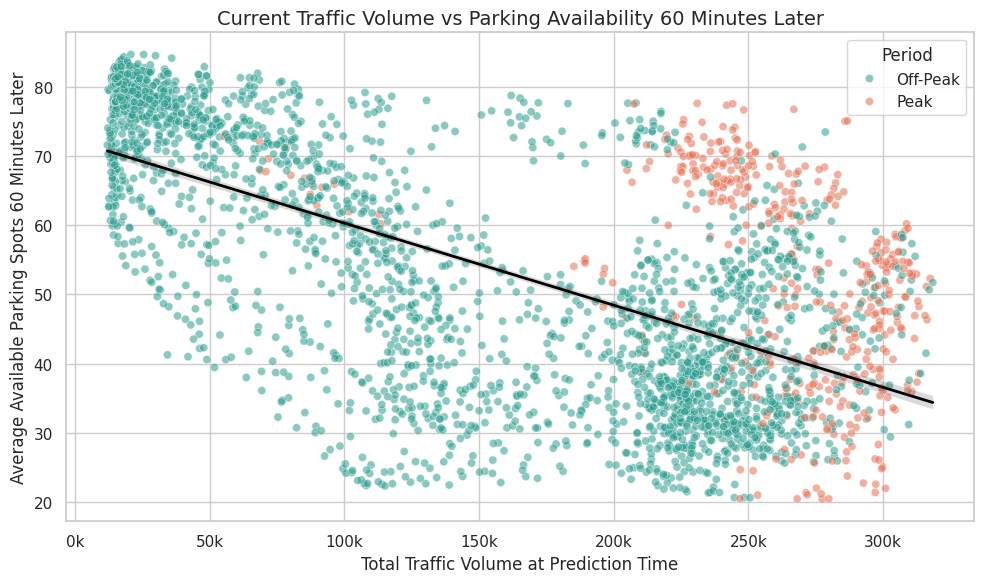

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from pyspark.sql import functions as F

# Aggregate parking availability across areas for each timestamp.
# Traffic volume is identical across areas at the same timestamp,
# so max() retrieves the shared value without repeatedly counting it.
traffic_availability_df = (
    engineered_df
    .groupBy("target_time", "Peak_Period")
    .agg(
        F.max("total_traffic_volume").alias("total_traffic_volume"),
        F.avg("available_spots").alias("avg_available_spots")
    )
    .orderBy("target_time")
)

print(
    "Aggregated rows:",
    traffic_availability_df.count()
)

traffic_parking_correlation = traffic_availability_df.stat.corr(
    "total_traffic_volume",
    "avg_available_spots"
)

print(
    "Pearson correlation:",
    round(traffic_parking_correlation, 4)
)

# Pandas is used only after PySpark aggregation.
traffic_availability_pd = traffic_availability_df.toPandas()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

ax = sns.scatterplot(
    data=traffic_availability_pd,
    x="total_traffic_volume",
    y="avg_available_spots",
    hue="Peak_Period",
    hue_order=["Off-Peak", "Peak"],
    palette={
        "Off-Peak": "#2A9D8F",
        "Peak": "#E76F51"
    },
    alpha=0.55,
    s=35
)

# Add an overall linear trend line.
sns.regplot(
    data=traffic_availability_pd,
    x="total_traffic_volume",
    y="avg_available_spots",
    scatter=False,
    color="black",
    line_kws={
        "linewidth": 2,
        "label": "Overall trend"
    }
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value / 1000:.0f}k")
)

plt.title(
    "Current Traffic Volume vs Parking Availability "
    "60 Minutes Later",
    fontsize=14
)
plt.xlabel(
    "Total Traffic Volume at Prediction Time"
)
plt.ylabel(
    "Average Available Parking Spots 60 Minutes Later"
)
plt.legend(title="Period")
plt.tight_layout()
plt.show()

This plot examines the relationship between traffic volume observed at `traffic_time` and average parking availability 60 minutes later at `target_time`, separated into peak and off-peak target periods. It shows an overall negative relationship between total traffic volume and average parking availability. As traffic volume increases, the average number of available parking spots generally decreases. However, the wide spread of observations indicates that the relationship is not purely linear. Peak-period observations are concentrated mainly at higher traffic levels, but they still overlap with off-peak observations. This suggests that traffic volume alone cannot fully explain parking availability. For model training, traffic volume should be combined with temporal features such as hour, day of week, and Peak_Period. The non-linear pattern also supports the use of tree-based regression models, such as Random Forest and GBT, rather than relying only on a simple linear relationship.

Heatmap aggregated rows: 168


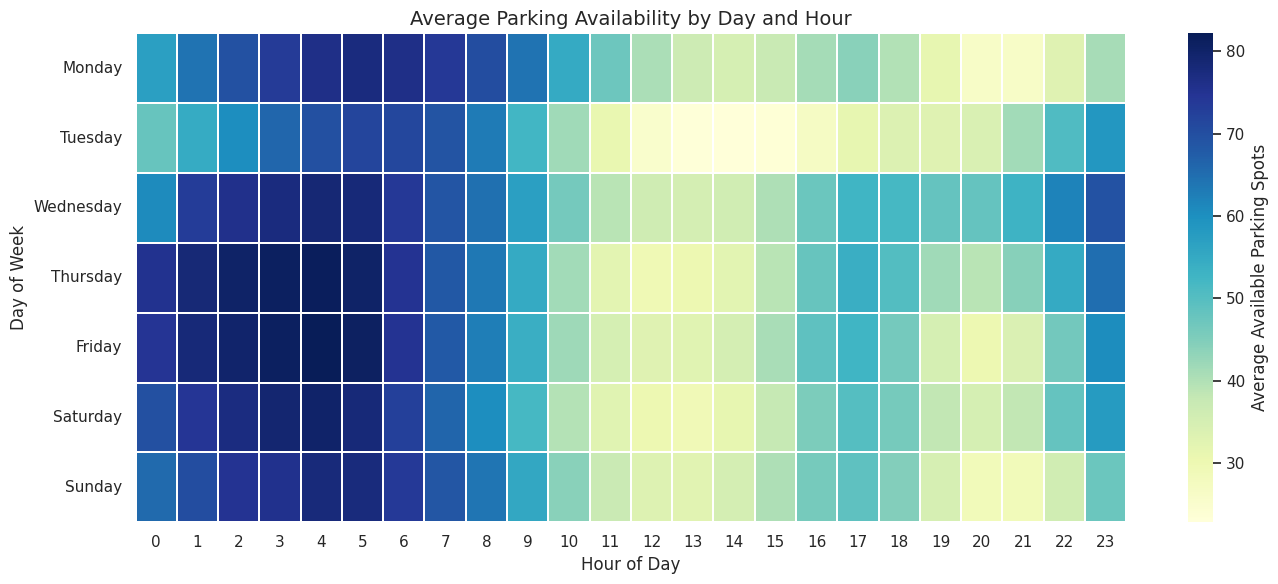

In [48]:
# Aggregate average parking availability by day of week and hour.
temporal_availability_df = (
    engineered_df
    .groupBy("day_of_week", "hour")
    .agg(
        F.avg("available_spots").alias(
            "avg_available_spots"
        )
    )
    .orderBy("day_of_week", "hour")
)

print(
    "Heatmap aggregated rows:",
    temporal_availability_df.count()
)

# Only the 7 × 24 aggregated result is converted to Pandas.
temporal_availability_pd = temporal_availability_df.toPandas()

day_name_mapping = {
    1: "Sunday",
    2: "Monday",
    3: "Tuesday",
    4: "Wednesday",
    5: "Thursday",
    6: "Friday",
    7: "Saturday"
}

temporal_availability_pd["day_name"] = (
    temporal_availability_pd["day_of_week"]
    .map(day_name_mapping)
)

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

availability_heatmap = (
    temporal_availability_pd
    .pivot(
        index="day_name",
        columns="hour",
        values="avg_available_spots"
    )
    .reindex(day_order)
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    availability_heatmap,
    cmap="YlGnBu",
    linewidths=0.2,
    cbar_kws={
        "label": "Average Available Parking Spots"
    }
)

plt.title(
    "Average Parking Availability by Day and Hour",
    fontsize=14
)
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()

This heatmap shows how average parking availability changes across hours of the day and days of the week. It shows a clear temporal pattern in parking availability. Average availability is generally highest during the early morning hours, especially between midnight and approximately 07:00. It decreases after the morning commuting period and remains relatively low during much of the daytime and early evening before increasing again at night. The pattern also varies across days of the week, indicating an interaction between hour and day_of_week. Therefore, both temporal features should be retained for model training. Peak_Period provides a useful summary of commuting periods, but it cannot represent all hourly and daily variations shown in the heatmap. Tree-based models can learn these temporal interactions and non-linear changes without assuming a constant relationship.

## Part 2. Feature extraction and ML training <a class="anchor" name="part-2"></a>
In this section, you must use PySpark DataFrame functions and ML packages for data preparation, model building, and evaluation. Other ML packages, such as scikit-learn, should not be used to process the data; however, it’s fine to use them to display the result or evaluate your model.  
### 2.1 Feature Selection & Justification (10%)
Review the columns across the joined datasets. In a markdown cell, provide a structured discussion (maximum 300 words):  
- Identify which specific columns represent noise or distractors for the target label and explain why they should be excluded.  
- Justify the predictive features you have selected for your feature vector.  
- Detail the transformations required (e.g., index encoding, one-hot encoding, vector scaling) before vector assembly.  
Write the PySpark DataFrame code to assemble your filtered feature set.  


### Feature Selection and Justification

The original traffic dataset contains separate records for each timestamp, site, heading, vehicle class, and speed bin, whereas the target represents parking availability for one area in one 15-minute target interval. Traffic records were first aggregated to 15-minute resolution. Traffic features observed at `traffic_time` were then aligned with `available_spots` at `target_time`, where the target occurs 60 minutes after the observed traffic conditions. This establishes a forward-looking prediction task and prevents the same parking label from being repeated across raw traffic records.

Raw identifiers such as `id`, `deviceid`, `signplateid`, `streetid`, and `bayid` were excluded because their numeric values do not represent meaningful quantities. The traffic `site` identifier was also excluded because the supplied metadata does not provide a reliable direct mapping between individual traffic sites and parking areas. Raw `traffic_time` and `target_time` values were not placed directly into the feature vector. Instead, `hour`, `day_of_week`, and `Peak_Period`, derived from the target period, were used to represent temporal patterns.

`heading` was summarised into northbound, southbound, eastbound, and westbound traffic volumes. `vehicle_class` was transformed into `heavy_vehicle_ratio`. The related `heavy_vehicle_volume` feature was excluded because it can be reconstructed from `total_traffic_volume` and `heavy_vehicle_ratio`. `speed_bin` was excluded to avoid introducing numerous interval categories and midpoint assumptions; traffic volume and direction were retained as the main congestion indicators.

`occupied_spots`, `arrivals`, and `departures` from the target period were excluded because they contain direct information about the parking outcome and would cause target leakage. `zone_capacity` was retained because parking availability depends on the number of bays in each area.

Categorical features are processed using `StringIndexer` and `OneHotEncoder`, and all selected features are combined using `VectorAssembler`. Feature scaling is unnecessary because Random Forest and Gradient-Boosted Trees make split-based decisions rather than distance-based calculations.

In [49]:
from pyspark.sql import functions as F

label_column = "available_spots"

categorical_features = [
    "areaid",
    "hour",
    "day_of_week",
    "Peak_Period"
]

numerical_features = [
    "zone_capacity",
    "total_traffic_volume",
    "northbound_volume",
    "southbound_volume",
    "eastbound_volume",
    "westbound_volume",
    "traffic_pressure_ratio",
    "heavy_vehicle_ratio"
]

selected_columns = (
    categorical_features
    + numerical_features
    + [label_column]
)

model_df = (
    engineered_df
    .select(*selected_columns)
    .dropna(subset=selected_columns)
)

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTarget label:")
print(label_column)

print("\nModel row count:")
print(model_df.count())

Categorical features:
['areaid', 'hour', 'day_of_week', 'Peak_Period']

Numerical features:
['zone_capacity', 'total_traffic_volume', 'northbound_volume', 'southbound_volume', 'eastbound_volume', 'westbound_volume', 'traffic_pressure_ratio', 'heavy_vehicle_ratio']

Target label:
available_spots

Model row count:
106384


In [50]:
model_df.printSchema()

model_df.show(
    5,
    truncate=False
)

root
 |-- areaid: integer (nullable = true)
 |-- hour: integer (nullable = false)
 |-- day_of_week: integer (nullable = false)
 |-- Peak_Period: string (nullable = false)
 |-- zone_capacity: double (nullable = true)
 |-- total_traffic_volume: long (nullable = true)
 |-- northbound_volume: long (nullable = true)
 |-- southbound_volume: long (nullable = true)
 |-- eastbound_volume: long (nullable = true)
 |-- westbound_volume: long (nullable = true)
 |-- traffic_pressure_ratio: double (nullable = true)
 |-- heavy_vehicle_ratio: double (nullable = true)
 |-- available_spots: double (nullable = true)

+------+----+-----------+-----------+-------------+--------------------+-----------------+-----------------+----------------+----------------+----------------------+-------------------+---------------+
|areaid|hour|day_of_week|Peak_Period|zone_capacity|total_traffic_volume|northbound_volume|southbound_volume|eastbound_volume|westbound_volume|traffic_pressure_ratio|heavy_vehicle_ratio|availabl

In [51]:
model_df.select(
    [
        F.sum(
            F.col(column).isNull().cast("int")
        ).alias(column)
        for column in selected_columns
    ]
).show(truncate=False)

+------+----+-----------+-----------+-------------+--------------------+-----------------+-----------------+----------------+----------------+----------------------+-------------------+---------------+
|areaid|hour|day_of_week|Peak_Period|zone_capacity|total_traffic_volume|northbound_volume|southbound_volume|eastbound_volume|westbound_volume|traffic_pressure_ratio|heavy_vehicle_ratio|available_spots|
+------+----+-----------+-----------+-------------+--------------------+-----------------+-----------------+----------------+----------------+----------------------+-------------------+---------------+
|0     |0   |0          |0          |0            |0                   |0                |0                |0               |0               |0                     |0                  |0              |
+------+----+-----------+-----------+-------------+--------------------+-----------------+-----------------+----------------+----------------+----------------------+-------------------+-------

### 2.2 Preparing Spark ML Pipelines (10%)  <a class="anchor" name="2.2"></a>

Construct the required data transformation stages using PySpark MLlib:  
- StringIndexer and OneHotEncoder for non-ordinal categorical features.  
- VectorAssembler to combine all numerical and encoded categorical columns into a single features vector.  
- Perform scaling and normalisation as appropriate.  
(Note: If you have already created those transformations, you can use them directly in the pipelines.)  
Define two ML Estimators configured for continuous label regression:  
- Pipeline 1: RandomForestRegressor  
- Pipeline 2: GBTRegressor (Gradient-Boosted Tree Regressor)  
Assemble each estimator with your feature transformation stages into two clean, end-to-end pipeline objects. Do not call .fit() or .transform() at this stage.  


In [52]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)
from pyspark.ml.regression import (
    RandomForestRegressor,
    GBTRegressor
)

# Create one StringIndexer for each categorical feature.
indexers = [
    StringIndexer(
        inputCol=column,
        outputCol=f"{column}_index",
        handleInvalid="keep"
    )
    for column in categorical_features
]

indexed_columns = [
    f"{column}_index"
    for column in categorical_features
]

encoded_columns = [
    f"{column}_encoded"
    for column in categorical_features
]

encoder = OneHotEncoder(
    inputCols=indexed_columns,
    outputCols=encoded_columns,
    handleInvalid="keep"
)

In [53]:
assembler_inputs = (
    encoded_columns
    + numerical_features
)

assembler = VectorAssembler(
    inputCols=assembler_inputs,
    outputCol="features",
    handleInvalid="keep"
)

print("VectorAssembler inputs:")
print(assembler_inputs)

VectorAssembler inputs:
['areaid_encoded', 'hour_encoded', 'day_of_week_encoded', 'Peak_Period_encoded', 'zone_capacity', 'total_traffic_volume', 'northbound_volume', 'southbound_volume', 'eastbound_volume', 'westbound_volume', 'traffic_pressure_ratio', 'heavy_vehicle_ratio']


In [54]:
rf_regressor = RandomForestRegressor(
    labelCol="available_spots",
    featuresCol="features",
    predictionCol="prediction",
    seed=2026
)

gbt_regressor = GBTRegressor(
    labelCol="available_spots",
    featuresCol="features",
    predictionCol="prediction",
    seed=2026
)

In [55]:
preprocessing_stages = (
    indexers
    + [encoder, assembler]
)

rf_pipeline = Pipeline(
    stages=preprocessing_stages
    + [rf_regressor]
)

gbt_pipeline = Pipeline(
    stages=preprocessing_stages
    + [gbt_regressor]
)

In [56]:
print("Random Forest Pipeline:")

for position, stage in enumerate(
    rf_pipeline.getStages(),
    start=1
):
    print(
        position,
        stage.__class__.__name__
    )

print("\nGBT Pipeline:")

for position, stage in enumerate(
    gbt_pipeline.getStages(),
    start=1
):
    print(
        position,
        stage.__class__.__name__
    )

Random Forest Pipeline:
1 StringIndexer
2 StringIndexer
3 StringIndexer
4 StringIndexer
5 OneHotEncoder
6 VectorAssembler
7 RandomForestRegressor

GBT Pipeline:
1 StringIndexer
2 StringIndexer
3 StringIndexer
4 StringIndexer
5 OneHotEncoder
6 VectorAssembler
7 GBTRegressor


### 2.3 Model Training and Evaluation (15%)

2.3.1 Data Splitting: Split your consolidated dataset into training (70%) and testing (30%) subsets using seed=2026.

In [57]:
from pyspark import StorageLevel

train_df, test_df = model_df.randomSplit(
    [0.7, 0.3],
    seed=2026
)

# The two datasets will be reused by both models.
train_df = train_df.persist(
    StorageLevel.MEMORY_AND_DISK
)

test_df = test_df.persist(
    StorageLevel.MEMORY_AND_DISK
)

train_count = train_df.count()
test_count = test_df.count()
total_count = train_count + test_count

print("Training rows:", train_count)
print("Testing rows:", test_count)
print("Total rows:", total_count)

print(
    "Training percentage:",
    round(train_count / total_count * 100, 2),
    "%"
)

print(
    "Testing percentage:",
    round(test_count / total_count * 100, 2),
    "%"
)

[Stage 268:======================================>             (148 + 26) / 200]

Training rows: 74314
Testing rows: 32070
Total rows: 106384
Training percentage: 69.85 %
Testing percentage: 30.15 %


2.3.2 Metric Discussion: Discuss the evaluation metrics you will use to evaluate your regression models (e.g., Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), R^2, etc.). Explain why you chose those metrics over others.

Three complementary regression metrics are used. RMSE is the primary
optimisation metric because it gives greater weight to large prediction
errors. This is important for parking forecasting because a large error may
send many drivers towards an area with substantially fewer available spaces
than predicted. MAE reports the average absolute error in units of parking
spaces and is therefore easier to interpret operationally. R² measures the
proportion of variation in parking availability explained by the model and
provides a scale-independent measure of overall fit.

MSE is not reported separately because it contains the same squared-error
information as RMSE but is expressed in squared parking-space units, making it
less interpretable. MAPE is not selected because available_spots can equal
zero, causing undefined or unstable percentage errors. A better model should
therefore have lower RMSE and MAE and a higher R².

2.3.3 Pipeline Fitting & Comparison: Train both pipelines on the training split. Evaluate their performance on the unseen test split using RegressionEvaluator.  
Present a side-by-side comparison table of the evaluation metrics, analyse why one algorithm outperformed the other, and save the superior pipeline model to disk. (You will load this model in Assignment 2B).  
(Note: You may need to go through a few training loops or use more data to create a better-performing model.)

In [58]:
import time

rf_start_time = time.perf_counter()

rf_model = rf_pipeline.fit(train_df)

rf_training_seconds = (
    time.perf_counter() - rf_start_time
)

print(
    "Random Forest training time:",
    round(rf_training_seconds, 2),
    "seconds"
)

[Stage 353:===================================================> (194 + 6) / 200]

Random Forest training time: 20.08 seconds


In [59]:
gbt_start_time = time.perf_counter()

gbt_model = gbt_pipeline.fit(train_df)

gbt_training_seconds = (
    time.perf_counter() - gbt_start_time
)

print(
    "GBT training time:",
    round(gbt_training_seconds, 2),
    "seconds"
)

[Stage 810:========================================>           (157 + 26) / 200]

GBT training time: 102.85 seconds


In [60]:
from pyspark.ml.evaluation import RegressionEvaluator

rf_predictions = (
    rf_model
    .transform(test_df)
    .select("available_spots", "prediction")
    .cache()
)

gbt_predictions = (
    gbt_model
    .transform(test_df)
    .select("available_spots", "prediction")
    .cache()
)

# Materialise and cache the predictions.
rf_predictions.count()
gbt_predictions.count()

def evaluate_predictions(predictions):
    rmse = RegressionEvaluator(
        labelCol="available_spots",
        predictionCol="prediction",
        metricName="rmse"
    ).evaluate(predictions)

    mae = RegressionEvaluator(
        labelCol="available_spots",
        predictionCol="prediction",
        metricName="mae"
    ).evaluate(predictions)

    r2 = RegressionEvaluator(
        labelCol="available_spots",
        predictionCol="prediction",
        metricName="r2"
    ).evaluate(predictions)

    return rmse, mae, r2

rf_rmse, rf_mae, rf_r2 = evaluate_predictions(
    rf_predictions
)

gbt_rmse, gbt_mae, gbt_r2 = evaluate_predictions(
    gbt_predictions
)

comparison_df = spark.createDataFrame(
    [
        (
            "Random Forest",
            rf_rmse,
            rf_mae,
            rf_r2,
            rf_training_seconds
        ),
        (
            "GBT",
            gbt_rmse,
            gbt_mae,
            gbt_r2,
            gbt_training_seconds
        )
    ],
    [
        "Model",
        "RMSE",
        "MAE",
        "R2",
        "Training_Time_Seconds"
    ]
)

comparison_df.select(
    "Model",
    F.round("RMSE", 4).alias("RMSE"),
    F.round("MAE", 4).alias("MAE"),
    F.round("R2", 4).alias("R2"),
    F.round(
        "Training_Time_Seconds", 2
    ).alias("Training_Time_Seconds")
).show(truncate=False)

+-------------+-------+-------+------+---------------------+
|Model        |RMSE   |MAE    |R2    |Training_Time_Seconds|
+-------------+-------+-------+------+---------------------+
|Random Forest|24.4948|15.2372|0.9095|20.08                |
|GBT          |19.4819|10.9828|0.9428|102.85               |
+-------------+-------+-------+------+---------------------+



In [61]:
rmse_reduction = (
    (rf_rmse - gbt_rmse)
    / rf_rmse
    * 100
)

mae_reduction = (
    (rf_mae - gbt_mae)
    / rf_mae
    * 100
)

r2_increase = gbt_r2 - rf_r2

print(
    "GBT RMSE reduction relative to RF:",
    round(rmse_reduction, 2),
    "%"
)

print(
    "GBT MAE reduction relative to RF:",
    round(mae_reduction, 2),
    "%"
)

print(
    "GBT R2 increase relative to RF:",
    round(r2_increase, 4)
)

GBT RMSE reduction relative to RF: 20.47 %
GBT MAE reduction relative to RF: 27.92 %
GBT R2 increase relative to RF: 0.0332


GBT achieved the best predictive performance on the unseen test set. Compared
with Random Forest, GBT reduced RMSE by approximately 20.47% and MAE by
27.92%. R² increased from 0.9095 to 0.9428, indicating that GBT explained a
larger proportion of the variation in parking availability.

GBT builds trees sequentially, with each new tree focusing on residual errors
from the preceding ensemble. This allows it to capture complex non-linear
interactions between location, time, fixed parking capacity, traffic volume,
traffic direction, and vehicle composition more effectively than the baseline
Random Forest. However, the improvement came with a computational cost: GBT training required 102.85 seconds compared with 20.08 seconds for Random Forest, making it approximately 5.12 times slower. Since predictive accuracy is the
primary objective, GBT is selected as the superior baseline model for
hyperparameter tuning in Part 3.

In [62]:
baseline_model_path = (
    "models/best_gbt_baseline_model"
)

gbt_model.write().overwrite().save(
    baseline_model_path
)

print(
    "Baseline GBT model saved to:",
    baseline_model_path
)

Baseline GBT model saved to: models/best_gbt_baseline_model


In [63]:
rf_predictions.unpersist()
gbt_predictions.unpersist()

DataFrame[available_spots: double, prediction: double]

### Part 3: Performance Tuning (35%) <a class="anchor" name="part-3"></a>  
Apply the techniques you have learnt from the labs, for example, CrossValidator, TrainValidationSplit, ParamGridBuilder, etc., to perform further hyperparameter tuning and model optimisation.  
The assessment is based on the quality of your work/process, not the quality of your model. Please include your thoughts/ideas/discussions.

Using the superior model pipeline identified in Part 2, perform systematic hyperparameter tuning to optimise predictive accuracy.  
1. Search Grid & Cross-Validation: Construct a parameter grid, and select at least two hyperparameters to tune (e.g., maxDepth, numTrees/maxIter, or stepSize/minInstancesPerNode).


In [64]:
from pyspark.ml.tuning import (
    ParamGridBuilder,
    TrainValidationSplit
)
from pyspark.ml.evaluation import (
    RegressionEvaluator
)

rmse_evaluator = RegressionEvaluator(
    labelCol="available_spots",
    predictionCol="prediction",
    metricName="rmse"
)

gbt_param_grid = (
    ParamGridBuilder()
    .addGrid(
        gbt_regressor.maxDepth,
        [3, 5, 7]
    )
    .addGrid(
        gbt_regressor.maxIter,
        [20, 40]
    )
    .build()
)

print(
    "Number of parameter combinations:",
    len(gbt_param_grid)
)

Number of parameter combinations: 6


2. Configure a CrossValidator with either k-fold cross-validation or TrainValidationSplit, using the metrics you suggested as the primary optimisation metric.


In [65]:
gbt_tuner = TrainValidationSplit(
    estimator=gbt_pipeline,
    estimatorParamMaps=gbt_param_grid,
    evaluator=rmse_evaluator,
    trainRatio=0.8,
    parallelism=1,
    seed=2026
)

tuning_start_time = time.perf_counter()

gbt_tuned_model = gbt_tuner.fit(
    train_df
)

tuning_seconds = (
    time.perf_counter()
    - tuning_start_time
)

print(
    "Total tuning time:",
    round(tuning_seconds, 2),
    "seconds"
)

[Stage 6045:=======================================>           (153 + 27) / 200]

Total tuning time: 1553.13 seconds


In [66]:
validation_rows = []

for params, metric in zip(
    gbt_param_grid,
    gbt_tuned_model.validationMetrics
):
    validation_rows.append(
        (
            int(
                params[
                    gbt_regressor.maxDepth
                ]
            ),
            int(
                params[
                    gbt_regressor.maxIter
                ]
            ),
            float(metric)
        )
    )

validation_results_df = (
    spark.createDataFrame(
        validation_rows,
        [
            "maxDepth",
            "maxIter",
            "Validation_RMSE"
        ]
    )
    .orderBy("Validation_RMSE")
)

validation_results_df.show(
    truncate=False
)

[Stage 6046:>                                                     (0 + 24) / 24]

+--------+-------+------------------+
|maxDepth|maxIter|Validation_RMSE   |
+--------+-------+------------------+
|7       |40     |15.443906968889275|
|7       |20     |16.975361662910984|
|5       |40     |18.0340255179185  |
|5       |20     |19.80631910986533 |
|3       |40     |22.214864637102632|
|3       |20     |24.08176874025259 |
+--------+-------+------------------+



3. Process Documentation & Analysis:
In a markdown cell, document:  
- The parameters and value ranges tested in your grid.  
- The computational cost and observed convergence behaviour across folds.  
- The quantitative performance gain achieved relative to your baseline model from Part 2.  

In [67]:
best_tuned_pipeline = (
    gbt_tuned_model.bestModel
)

best_gbt_stage = (
    best_tuned_pipeline.stages[-1]
)

print(
    "Selected maxDepth:",
    best_gbt_stage.getMaxDepth()
)

print(
    "Selected maxIter:",
    best_gbt_stage.getMaxIter()
)

tuned_predictions = (
    best_tuned_pipeline
    .transform(test_df)
    .select(
        "available_spots",
        "prediction"
    )
    .cache()
)

tuned_predictions.count()

tuned_rmse, tuned_mae, tuned_r2 = (
    evaluate_predictions(
        tuned_predictions
    )
)

Selected maxDepth: 7
Selected maxIter: 40


In [68]:
final_comparison_df = (
    spark.createDataFrame(
        [
            (
                "Baseline GBT",
                gbt_rmse,
                gbt_mae,
                gbt_r2
            ),
            (
                "Tuned GBT",
                tuned_rmse,
                tuned_mae,
                tuned_r2
            )
        ],
        [
            "Model",
            "RMSE",
            "MAE",
            "R2"
        ]
    )
)

final_comparison_df.select(
    "Model",
    F.round("RMSE", 4).alias("RMSE"),
    F.round("MAE", 4).alias("MAE"),
    F.round("R2", 4).alias("R2")
).show(truncate=False)

rmse_improvement = (
    (gbt_rmse - tuned_rmse)
    / gbt_rmse
    * 100
)

mae_improvement = (
    (gbt_mae - tuned_mae)
    / gbt_mae
    * 100
)

r2_change = tuned_r2 - gbt_r2

print(
    "RMSE improvement:",
    round(rmse_improvement, 2),
    "%"
)

print(
    "MAE improvement:",
    round(mae_improvement, 2),
    "%"
)

print(
    "R2 increase:",
    round(r2_change, 4)
)

+------------+-------+-------+------+
|Model       |RMSE   |MAE    |R2    |
+------------+-------+-------+------+
|Baseline GBT|19.4819|10.9828|0.9428|
|Tuned GBT   |15.4414|8.4502 |0.964 |
+------------+-------+-------+------+

RMSE improvement: 20.74 %
MAE improvement: 23.06 %
R2 increase: 0.0213


Six GBT parameter combinations were evaluated using maxDepth values of 3, 5,
and 7 and maxIter values of 20 and 40. These parameters control complementary
aspects of model complexity: maxDepth determines the complexity of each
individual tree, while maxIter controls the number of sequential boosting
iterations.

TrainValidationSplit used 80% of the original training set for candidate model
fitting and 20% for validation, with seed=2026 and RMSE as the primary
optimisation metric. The search used parallelism=1 to reduce peak memory usage.
The complete tuning process required 1553.13 seconds, or approximately 25.89 minutes. Because TrainValidationSplit was selected, performance was compared
across parameter configurations on one validation split rather than across
multiple cross-validation folds.

Validation RMSE improved consistently as both tree depth and iteration count
increased. For maxDepth values of 3, 5, and 7, increasing maxIter from 20 to 40
reduced validation RMSE from 24.0818 to 22.2149, from 19.8063 to 18.0340, and
from 16.9754 to 15.4439, respectively. The best configuration was
maxDepth=7 and maxIter=40, with a validation RMSE of 15.4439. Since the best
values occurred at the upper boundary of the grid, performance had not fully
reached a plateau. However, expanding the grid would substantially increase
computational cost and could increase overfitting risk.

On the unseen test set, the tuned GBT reduced RMSE from 19.4819 to 15.4414,
an improvement of 20.74%. MAE decreased from 10.9828 to 8.4502, an improvement
of 23.06%, while R² increased from 0.9428 to 0.9640. The close agreement
between the validation RMSE of 15.4439 and test RMSE of 15.4414 also indicates
stable generalisation to unseen data. The tuned model therefore provides a
meaningful improvement over the baseline GBT and is selected as the final
pipeline for deployment in Assignment 2B.

4. Model Export: Save your finalised, tuned pipeline model to an export directory (e.g., models/best_tuned_parking_model).  
This persisted model will be directly deployed into your real-time Kafka streaming consumer in Assignment 2B.  
(note: If you don't complete the optimisation part, you can also use the model from part 2 in A2B.)

In [69]:
final_model_path = (
    "models/best_tuned_parking_model"
)

best_tuned_pipeline.write().overwrite().save(
    final_model_path
)

print(
    "Final tuned pipeline saved to:",
    final_model_path
)

Final tuned pipeline saved to: models/best_tuned_parking_model


## References:
Please add your references below:

### Course Material

Monash University (2026). *FIT5202 Data Processing for Big Data, Week 9 Lab: Movie Recommendation with Collaborative Filtering (ALS)*. Course material provided through Moodle.

### Software Documentation

Apache Spark (2026). *PySpark MLlib documentation: Machine Learning Pipelines, RegressionEvaluator, GBTRegressor, ParamGridBuilder, and TrainValidationSplit*.  
https://spark.apache.org/docs/latest/api/python/reference/pyspark.ml.html

### Generative AI Acknowledgement

OpenAI ChatGPT/Codex was used to clarify assignment requirements, troubleshoot the Docker and PySpark environment, suggest and review code structures, and improve written explanations. All suggestions were reviewed and adapted by the author, and all code, outputs, visualisations, and model results were independently executed and verified in the submitted notebook. 